In [41]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/reddit_ru.csv      
  inflating: data/tokenizer.pickle   
  inflating: data/model.keras        


In [44]:
import pandas as pd


df = pd.read_csv('data/reddit_ru.csv')
df = df.drop_duplicates()
df.head()

,comment
0,"I'm a bot, *bleep*, *bloop*. Someone has linke..."
1,[removed]
2,"Ваш пост был автоматически удален, потому что ..."
3,дурачок
4,Импорт закрыли => доллары тратить некуда => до...


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5753 entries, 0 to 5989
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   comment  5753 non-null   object
dtypes: object(1)
memory usage: 89.9+ KB


In [46]:
import re


def clean_text(text):
    text = text.lower()
    text = re.sub(r"\'s", " ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    text = text.strip(' ')
    return text

df['comment'] = df['comment'].apply(clean_text)
print(df.shape)
df.head()

(5753, 1)


,comment
0,i m a bot bleep bloop someone has linked to th...
1,removed
2,ваш пост был автоматически удален потому что в...
3,дурачок
4,импорт закрыли доллары тратить некуда доллары ...


In [47]:
# пропусков нет
df.isnull().sum()

,0
comment,0


In [48]:
# уберем сообщения с долей латинницы >= 0.4
is_en = lambda x: len(re.findall('[a-z]', x)) / max(len(x.replace(' ', '')), 1)
df = df[df['comment'].apply(is_en) < 0.4]
print(df.shape)

(5257, 1)


In [49]:
df.apply(lambda x: len(x['comment']), axis=1).describe()

,0
count,5257.000000
mean,99.858474
std,226.508365
min,0.000000
25%,22.000000
50%,47.000000
75%,102.000000
max,7866.000000


In [50]:
# уберем пустые комментарии и слишком длинные
df = df[df['comment'] != '']
df = df[(df['comment'].apply(lambda x: len(x)) < 300)]
df.shape

(4919, 1)

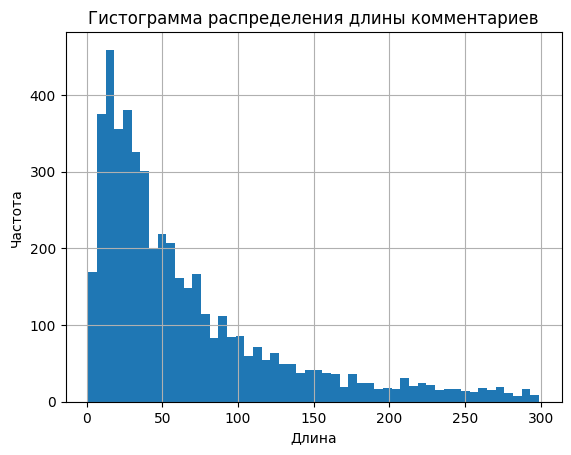

In [51]:
df.apply(lambda x: len(x['comment']), axis=1).hist(bins=52)
plt.xlabel('Длина')
plt.ylabel('Частота')
plt.title('Гистограмма распределения длины комментариев')
plt.show()

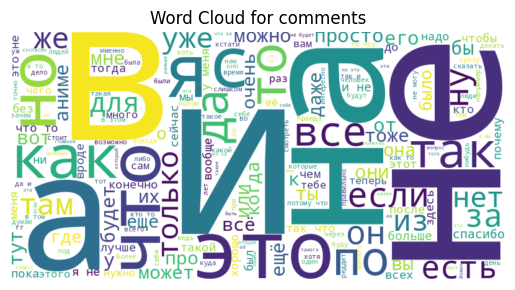

In [52]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

toxic_comments = ' '.join(df['comment'])
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(toxic_comments)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for comments')
plt.show()

In [53]:
import pickle
from tensorflow.keras.preprocessing.sequence import pad_sequences
from keras.models import load_model
import numpy as np

In [54]:
# взял модель с https://www.kaggle.com/code/egormanovel/toxic-comment-lstm/notebook, прогнал в гугл колабе, сериализовал модель и токенайзер для использования с нашим датасетом
# https://colab.research.google.com/drive/127pwYXMbmEg4xbcP23btVa6xp9yXAsyn?usp=sharing

model = load_model('data/model.keras')
with open('data/tokenizer.pickle', 'rb') as handle:
    tokenizer = pickle.load(handle)

In [55]:
X = tokenizer.texts_to_sequences(df['comment'].tolist())
max_comment_length = 300
X_pad = pad_sequences(X, maxlen=max_comment_length)

predictions = model.predict(X_pad,verbose=1)
toxic_comments = df[(np.round(predictions) == 1.0)]['comment'].tolist()
for comment in toxic_comments[0:20]:
    print(comment)

154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step
дурачок
ха ха я тут живу
где вы там бизнесменов видели одни пидарасы и жулики
а если кто то сам себе бармен кодироваться
а если его в поле закопать гандоны прорастут или сразу хуи будут по осени
ну а кому же ещё если вы знаете лично хоть одного росгвардейца и он вам кажется ок то знайте вы мудак нормальные люди им плюют в лицо при встрече а не жмут руку
просто цирк какой же стыд
а чей то у рамзанчика на лбу след от поцелуя боженьки
сайт эха заблочен но вроде венедиктов говорил что они остались и будут продолжать в соцсетях так что желательно давать альтернативные ссылки на их публикации
раша врет и пытается навредить ес в том числе используя тему короновируса и канал раша тудей европейская комиссия уже идентифицировала как минимум 150 скоординированных компаний по дезинформации из россии об этом и свежайший репортажик 1 го немецкого канала ard
і це чудово
россия не хотела в одну харю снижать добычу сейчас добычу снижают все члены опек есть разн

In [56]:
df['target'] = np.round(predictions)
df['target'].value_counts()

,count
target,
0.0,3291
1.0,1628


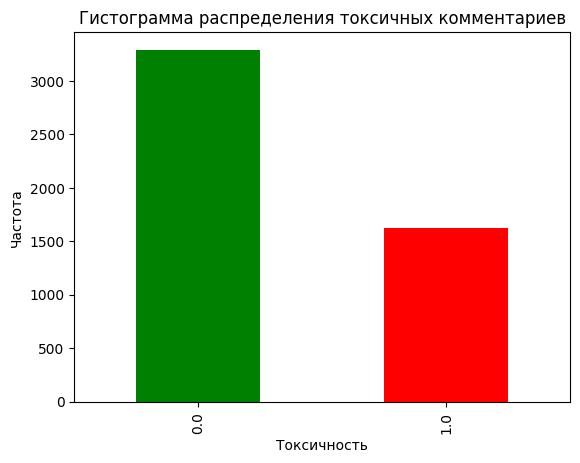

In [57]:
df['target'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()